In [1]:
import sys, numpy, pandas, sklearn, lightgbm, mlflow
print("Python    :", sys.version.split()[0])
print("Executable:", sys.executable)
print("numpy     :", numpy.__version__)
print("pandas    :", pandas.__version__)
print("sklearn   :", sklearn.__version__)
print("lightgbm  :", lightgbm.__version__)
print("mlflow    :", mlflow.__version__)

Python    : 3.11.8
Executable: C:\Users\hp\Documents\teliport_prototype\.venv\Scripts\python.exe
numpy     : 2.4.6
pandas    : 3.1.0
sklearn   : 1.9.1
lightgbm  : 4.7.0
mlflow    : 3.17.2


In [2]:
import sys
from pathlib import Path

PROJECT = Path.cwd().parent          # notebooks/ -> teliport_prototype/
assert (PROJECT / "src").exists(), f"Unexpected location: {PROJECT}"
sys.path.insert(0, str(PROJECT / "src"))

RAW = PROJECT / "data" / "raw"
CMAPSS_DIR = RAW / "CMAPSS"
CMAPSS_DIR.mkdir(parents=True, exist_ok=True)

%load_ext autoreload
%autoreload 2
print("Project root:", PROJECT)

Project root: C:\Users\hp\Documents\teliport_prototype


In [3]:
import zipfile, shutil, requests

URLS = [
    "https://data.nasa.gov/docs/legacy/CMAPSSData.zip",
    "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip",
]
EXPECTED = [f"{k}_FD00{i}.txt" for i in range(1, 5) for k in ("train", "test", "RUL")]

def have_all():
    return all((CMAPSS_DIR / f).exists() for f in EXPECTED)

def download(url, dest):
    with requests.get(url, stream=True, timeout=120,
                      headers={"User-Agent": "Mozilla/5.0"}) as r:
        r.raise_for_status()
        with open(dest, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    if not zipfile.is_zipfile(dest):
        raise ValueError("Downloaded file is not a valid zip")

def extract_recursive(zip_path, out_dir):
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(out_dir)
    done = set()
    while True:
        inner = [p for p in Path(out_dir).rglob("*.zip") if p not in done]
        if not inner:
            break
        for p in inner:
            with zipfile.ZipFile(p) as z:
                z.extractall(p.with_suffix(""))
            done.add(p)

if have_all():
    print("Dataset already present - skipping download.")
else:
    tmp = RAW / "_tmp"
    tmp.mkdir(exist_ok=True)
    zip_path = RAW / "cmapss_download.zip"
    for url in URLS:
        try:
            print("Downloading:", url)
            download(url, zip_path)
            extract_recursive(zip_path, tmp)
            for name in EXPECTED + ["readme.txt", "Damage Propagation Modeling.pdf"]:
                hits = list(tmp.rglob(name))
                if hits:
                    shutil.copy(hits[0], CMAPSS_DIR / name)
            if have_all():
                print("Success from:", url)
                break
        except Exception as e:
            print("  failed ->", e)
    shutil.rmtree(tmp, ignore_errors=True)
    zip_path.unlink(missing_ok=True)

print("All 12 files present:", have_all())
print(sorted(p.name for p in CMAPSS_DIR.iterdir()))

Downloading: https://data.nasa.gov/docs/legacy/CMAPSSData.zip
Success from: https://data.nasa.gov/docs/legacy/CMAPSSData.zip
All 12 files present: True
['Damage Propagation Modeling.pdf', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'readme.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


In [4]:
%%writefile ../src/cmapss_data.py
"""Loading utilities for the NASA C-MAPSS turbofan dataset."""
from pathlib import Path
import pandas as pd

ID_COLS = ["unit", "cycle"]
OP_COLS = ["op_setting_1", "op_setting_2", "op_setting_3"]
SENSOR_COLS = [f"s{i}" for i in range(1, 22)]
COLUMNS = ID_COLS + OP_COLS + SENSOR_COLS
SUBSETS = ["FD001", "FD002", "FD003", "FD004"]

SUBSET_INFO = {
    "FD001": {"conditions": 1, "fault_modes": 1},
    "FD002": {"conditions": 6, "fault_modes": 1},
    "FD003": {"conditions": 1, "fault_modes": 2},
    "FD004": {"conditions": 6, "fault_modes": 2},
}


def _read_txt(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep=r"\s+", header=None)
    df = df.iloc[:, : len(COLUMNS)].copy()
    df.columns = COLUMNS
    df[ID_COLS] = df[ID_COLS].astype(int)
    return df


def load_subset(fd: str, data_dir):
    """Return (train, test, rul_true) for one subset.

    train : run-to-failure rows with true RUL label (uncapped)
    test  : truncated trajectories (RUL unknown at row level)
    rul_true : one row per test unit -> true RUL at its last cycle
    """
    data_dir = Path(data_dir)
    train = _read_txt(data_dir / f"train_{fd}.txt")
    test = _read_txt(data_dir / f"test_{fd}.txt")

    rul = pd.read_csv(data_dir / f"RUL_{fd}.txt", sep=r"\s+", header=None).iloc[:, :1]
    rul.columns = ["RUL"]
    rul.insert(0, "unit", range(1, len(rul) + 1))

    units = sorted(test["unit"].unique())
    assert units == list(range(1, len(units) + 1)), "Test units not contiguous"
    assert len(rul) == len(units), "RUL file does not match test units"

    train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
    for df in (train, test, rul):
        df["subset"] = fd
    return train, test, rul


def load_all(data_dir, subsets=SUBSETS):
    return {fd: load_subset(fd, data_dir) for fd in subsets}

Writing ../src/cmapss_data.py


In [5]:
import numpy as np
import pandas as pd
from cmapss_data import load_all, OP_COLS, SENSOR_COLS, SUBSET_INFO

data = load_all(CMAPSS_DIR)

def n_regimes(df):
    r = df[OP_COLS].copy()
    r["op_setting_1"] = r["op_setting_1"].round(0) + 0.0
    r["op_setting_2"] = r["op_setting_2"].round(2) + 0.0
    r["op_setting_3"] = r["op_setting_3"].round(0) + 0.0
    return len(r.drop_duplicates())

rows = []
for fd, (train, test, rul) in data.items():
    life = train.groupby("unit")["cycle"].max()
    rows.append({
        "subset": fd,
        "train_engines": train["unit"].nunique(),
        "train_rows": len(train),
        "test_engines": test["unit"].nunique(),
        "test_rows": len(test),
        "missing_values": int(train.isna().sum().sum() + test.isna().sum().sum()),
        "op_regimes": n_regimes(train),
        "fault_modes": SUBSET_INFO[fd]["fault_modes"],
        "life_min": life.min(), "life_mean": round(life.mean(), 1), "life_max": life.max(),
        "test_true_RUL_mean": round(rul["RUL"].mean(), 1),
    })

summary = pd.DataFrame(rows).set_index("subset")
summary

,train_engines,train_rows,test_engines,test_rows,missing_values,op_regimes,fault_modes,life_min,life_mean,life_max,test_true_RUL_mean
subset,,,,,,,,,,,
FD001,100,20631,100,13096,0,1,1,128,206.3,362,75.5
FD002,260,53759,259,33991,0,6,1,128,206.8,378,81.2
FD003,100,24720,100,16596,0,1,2,145,247.2,525,75.3
FD004,249,61249,248,41214,0,6,2,128,246.0,543,86.6


In [6]:
import sys, warnings
from pathlib import Path
PROJECT = Path.cwd().parent
sys.path.insert(0, str(PROJECT / "src"))
%load_ext autoreload
%autoreload 2

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from cmapss_data import load_all, SENSOR_COLS

warnings.filterwarnings("ignore", message=".*constant.*")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
DATA_DIR = PROJECT / "data" / "raw" / "CMAPSS"
FIG_DIR = PROJECT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

data = load_all(DATA_DIR)
print("Loaded:", list(data))

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Loaded: ['FD001', 'FD002', 'FD003', 'FD004']


In [7]:
def regime_id(df):
    r = pd.DataFrame({
        "a": df["op_setting_1"].round(0) + 0.0,
        "b": df["op_setting_2"].round(2) + 0.0,
        "c": df["op_setting_3"].round(0) + 0.0,
    })
    return r.groupby(["a", "b", "c"]).ngroup()

def regime_normalize(df):
    out = df.copy()
    out["regime"] = regime_id(out)
    g = out.groupby("regime")[SENSOR_COLS]
    mu, sd = g.transform("mean"), g.transform("std")
    out[SENSOR_COLS] = ((out[SENSOR_COLS] - mu) / sd.where(sd > 1e-8)).fillna(0.0)
    return out

norm = {fd: regime_normalize(tr) for fd, (tr, te, rul) in data.items()}

def global_corr(df, s):
    return abs(df[s].corr(df["RUL"].clip(upper=125), method="spearman")) if df[s].std() > 0 else 0.0

def engine_trend(df, s):
    vals = []
    for _, e in df.groupby("unit"):
        x = e[s].rolling(10, min_periods=1).mean()
        vals.append(abs(x.corr(e["cycle"], method="spearman")) if x.std() > 0 else 0.0)
    return float(np.nanmean(vals))

glob  = pd.DataFrame({fd: [global_corr(df, s) for s in SENSOR_COLS] for fd, df in norm.items()}, index=SENSOR_COLS)
trend = pd.DataFrame({fd: [engine_trend(df, s) for s in SENSOR_COLS] for fd, df in norm.items()}, index=SENSOR_COLS)
scores = pd.concat({"global_|rho|": glob, "per_engine_trend": trend}, axis=1).fillna(0).round(2)

SELECTED = trend.fillna(0).index[(trend.fillna(0) >= 0.7).all(axis=1)].tolist()
print("Selected sensors:", SELECTED, len(SELECTED))
print("Dropped sensors :", [s for s in SENSOR_COLS if s not in SELECTED])
scores

Selected sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21'] 14
Dropped sensors : ['s1', 's5', 's6', 's10', 's16', 's18', 's19']


global_|rho|                   per_engine_trend                  
           FD001 FD002 FD003 FD004            FD001 FD002 FD003 FD004
s1          0.00  0.00  0.00  0.00             0.00  0.00  0.00  0.00
s2          0.63  0.59  0.64  0.54             0.88  0.86  0.83  0.81
s3          0.61  0.58  0.65  0.61             0.86  0.85  0.86  0.84
s4          0.70  0.68  0.71  0.67             0.93  0.91  0.89  0.89
s5          0.00  0.00  0.00  0.00             0.00  0.00  0.00  0.00
s6          0.12  0.36  0.18  0.20             0.28  0.73  0.45  0.64
s7          0.68  0.48  0.04  0.11             0.91  0.79  0.94  0.82
s8          0.57  0.38  0.71  0.53             0.84  0.74  0.91  0.78
s9          0.33  0.29  0.57  0.52             0.82  0.78  0.88  0.86
s10         0.00  0.07  0.45  0.22             0.00  0.35  0.69  0.52
s11         0.72  0.72  0.74  0.71             0.94  0.94  0.90  0.92
s12         0.70  0.50  0.05  0.11             0.93  0.81  0.95  0.84
s13         0.57  0.38  0.72  0.53             0.85  0.75  0.90  0.77
s14         0.21  0.16  0.47  0.43             0.83  0.82  0.88  0.87
s15         0.67  0.67  0.08  0.12             0.90  0.91  0.90  0.91
s16         0.00  0.20  0.00  0.13             0.00  0.46  0.00  0.38
s17         0.64  0.60  0.68  0.63             0.87  0.86  0.88  0.86
s18         0.00  0.00  0.00  0.00             0.00  0.00  0.00  0.00
s19         0.00  0.00  0.00  0.00             0.00  0.00  0.00  0.00
s20         0.66  0.45  0.08  0.06             0.90  0.77  0.88  0.74
s21         0.66  0.45  0.08  0.07             0.90  0.77  0.88  0.75

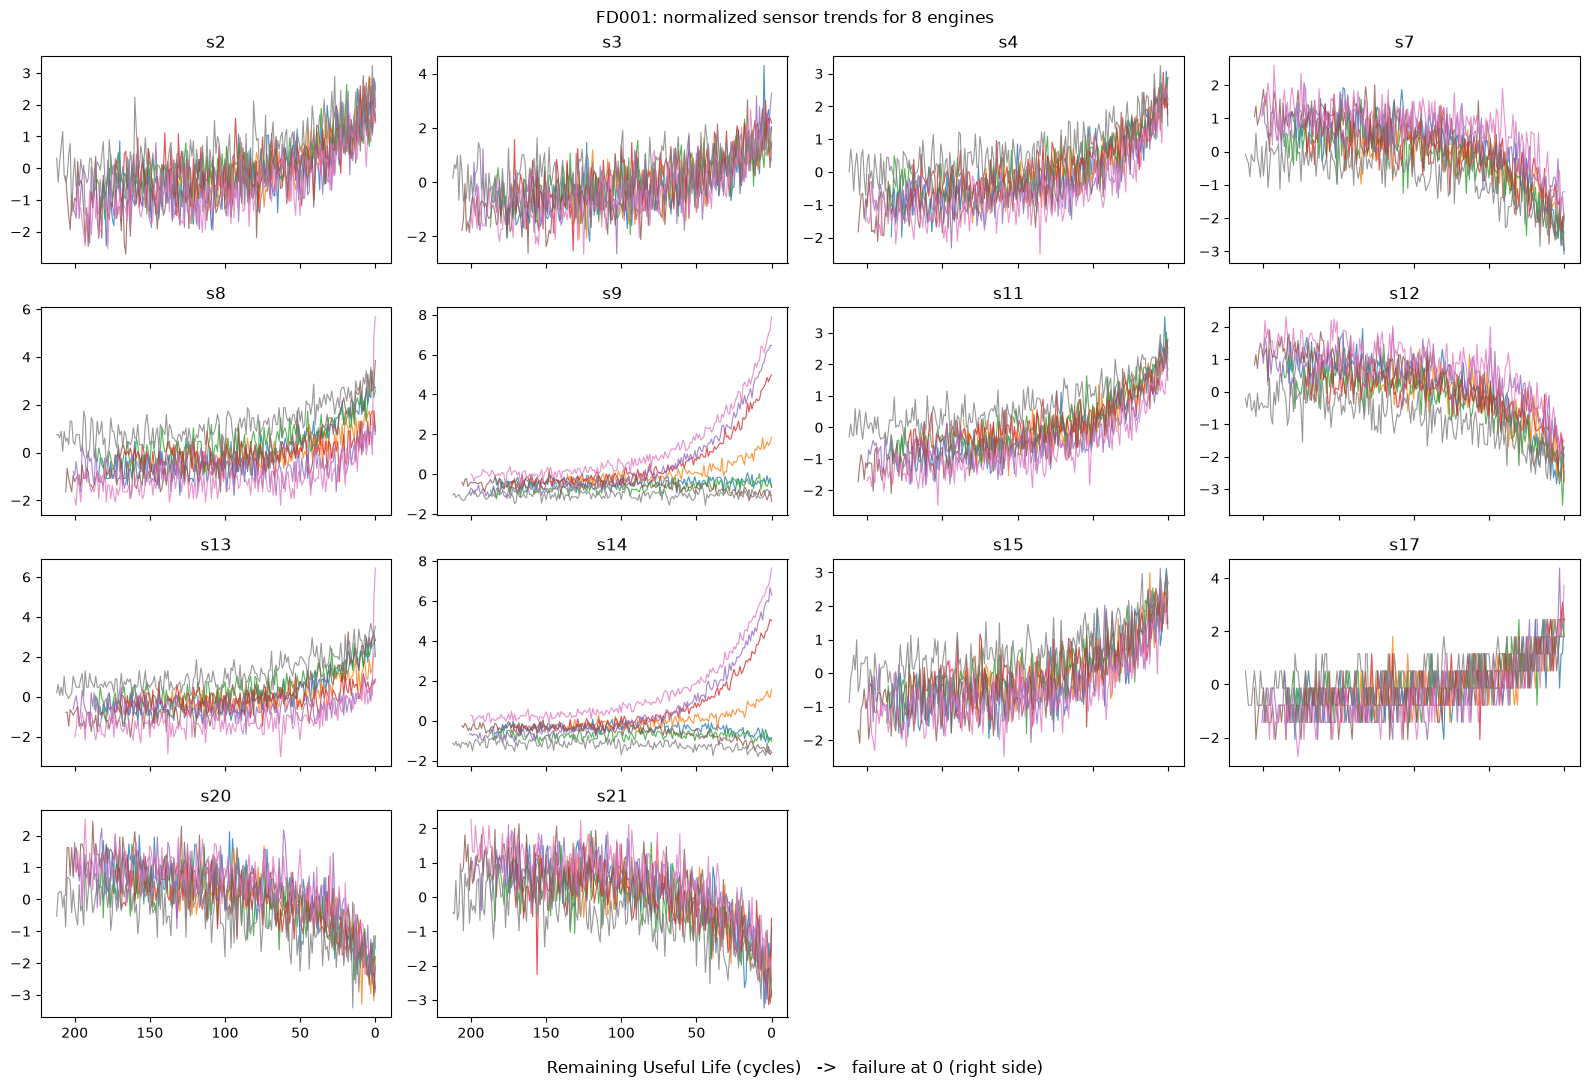

In [13]:
df = norm["FD001"]
rng = np.random.default_rng(42)
units = rng.choice(df["unit"].unique(), size=8, replace=False)
fig, axes = plt.subplots(4, 4, figsize=(16, 11), sharex=True)
for ax, s in zip(axes.ravel(), SELECTED):
    for u in units:
        e = df[df["unit"] == u]
        ax.plot(e["RUL"], e[s], lw=0.8, alpha=0.8)
    ax.set_title(s)
axes[0, 0].invert_xaxis()          # shared axis -> invert ONCE
for ax in axes.ravel()[len(SELECTED):]:
    ax.axis("off")
fig.supxlabel("Remaining Useful Life (cycles)   ->   failure at 0 (right side)")
fig.suptitle("FD001: normalized sensor trends for 8 engines")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_fd001_sensor_trends.png", bbox_inches="tight")
plt.show()

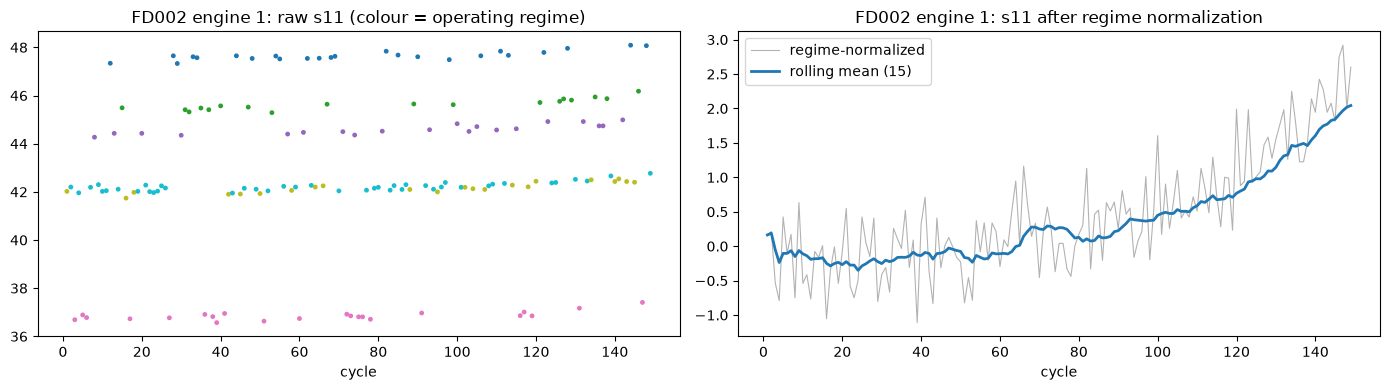

In [14]:
raw, nrm, u = data["FD002"][0], norm["FD002"], 1
e_raw, e_nrm = raw[raw["unit"] == u], nrm[nrm["unit"] == u]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].scatter(e_raw["cycle"], e_raw["s11"], s=6, c=e_nrm["regime"], cmap="tab10")
axes[0].set_title("FD002 engine 1: raw s11 (colour = operating regime)")
axes[1].plot(e_nrm["cycle"], e_nrm["s11"], lw=0.8, color="grey", alpha=0.6, label="regime-normalized")
axes[1].plot(e_nrm["cycle"], e_nrm["s11"].rolling(15, min_periods=1).mean(), lw=2, label="rolling mean (15)")
axes[1].set_title("FD002 engine 1: s11 after regime normalization"); axes[1].legend()
for ax in axes: ax.set_xlabel("cycle")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_fd002_regime_normalization.png", bbox_inches="tight")
plt.show()

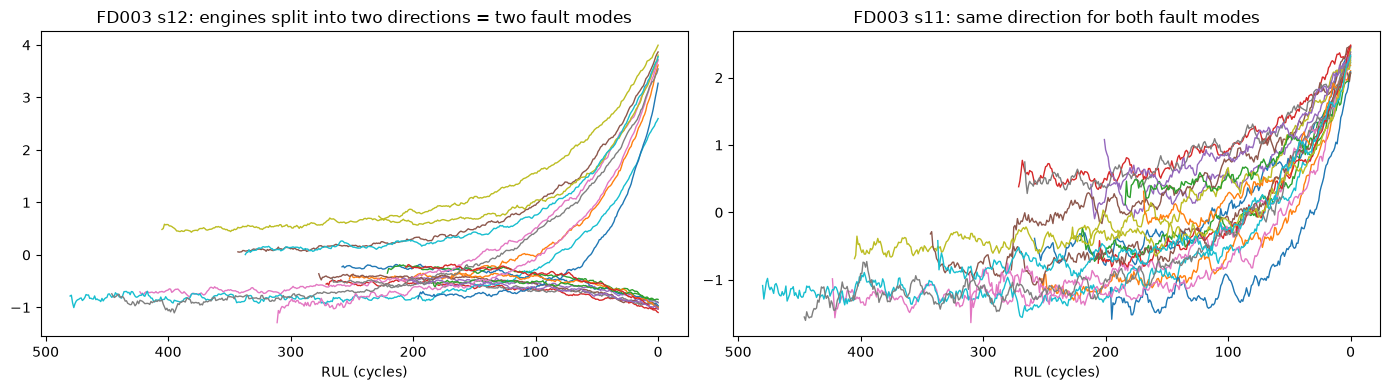

In [15]:
df = norm["FD003"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, s in zip(axes, ["s12", "s11"]):
    for u in range(1, 21):
        e = df[df["unit"] == u]
        ax.plot(e["RUL"], e[s].rolling(10, min_periods=1).mean(), lw=1)
    ax.invert_xaxis(); ax.set_xlabel("RUL (cycles)")
axes[0].set_title("FD003 s12: engines split into two directions = two fault modes")
axes[1].set_title("FD003 s11: same direction for both fault modes")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_fd003_two_fault_modes.png", bbox_inches="tight")
plt.show()

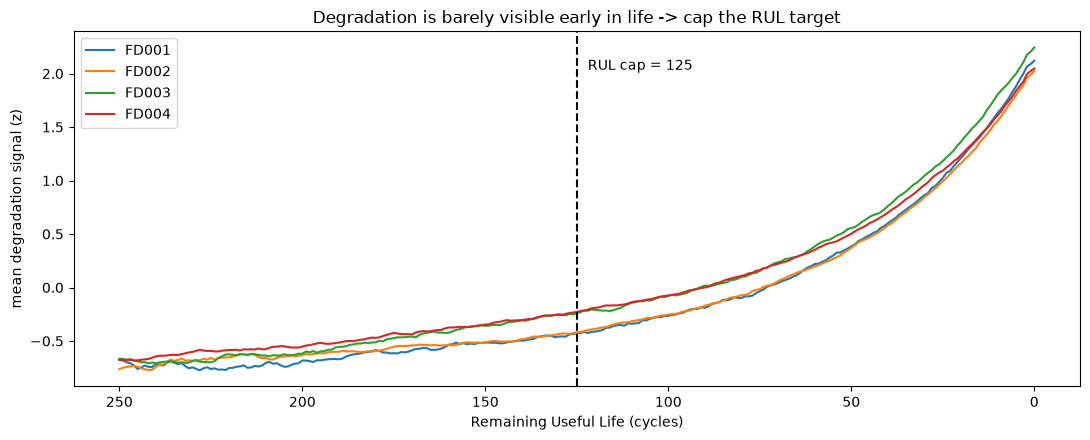

In [16]:
HI_SENS = ["s2", "s3", "s4", "s11", "s17"]
fig, ax = plt.subplots(figsize=(11, 4.5))
for fd, df in norm.items():
    curve = df[HI_SENS].mean(axis=1).groupby(df["RUL"]).mean().loc[:250]
    ax.plot(curve.index, curve.rolling(5, min_periods=1, center=True).mean(), label=fd)
ax.axvline(125, ls="--", c="k"); ax.text(122, ax.get_ylim()[1] * 0.85, "RUL cap = 125")
ax.invert_xaxis(); ax.set_xlabel("Remaining Useful Life (cycles)"); ax.set_ylabel("mean degradation signal (z)")
ax.set_title("Degradation is barely visible early in life -> cap the RUL target"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "04_rul_cap_evidence.png", bbox_inches="tight")
plt.show()

In [17]:
rows = []
for fd, (tr, te, rul) in data.items():
    rows.append({"subset": fd,
                 "train_rows_RUL<=15_%": round(100 * (tr["RUL"] <= 15).mean(), 1),
                 "train_rows_RUL<=30_%": round(100 * (tr["RUL"] <= 30).mean(), 1),
                 "test_engines": len(rul),
                 "test_engines_RUL<=30": int((rul["RUL"] <= 30).sum()),
                 "test_true_RUL_max": int(rul["RUL"].max())})
pd.DataFrame(rows).set_index("subset")

,train_rows_RUL<=15_%,train_rows_RUL<=30_%,test_engines,test_engines_RUL<=30,test_true_RUL_max
subset,,,,,
FD001,7.8,15.0,100,25,145
FD002,7.7,15.0,259,61,194
FD003,6.5,12.5,100,20,145
FD004,6.5,12.6,248,53,195
